# IR 1 — Vibe-code data examination and data carpentry

This is the hands-on workshop notebook. It consumes the Parquet table produced by **IR 0** (or the packaged, schema-equivalent rehearsal data), then writes three distinct artifacts for the next notebook: `IR_train.parquet`, `IR_validation.parquet`, and `IR_test.parquet`. It also writes a small `data_manifest.json` that records the selected labels, common spectral grid, split seed, and carpentry choices.

The supplied path is deliberately conservative: it validates arrays and identifiers, uses a shared 500-point grid, flags rather than silently removes spectral outliers, and does not resample classes by default. The prompts are the exercise. Make one auditable change at a time, rerun this notebook, and then run IR 2 unchanged to measure the effect. Validation and test examples are never rebalanced.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs/carpentry')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SCRAPER_OUTPUT = Path('outputs/nist_acquisition/IR_SMILES_functional_groups.parquet')
TRAIN_FILE = OUTPUT_DIR / 'IR_train.parquet'
VALIDATION_FILE = OUTPUT_DIR / 'IR_validation.parquet'
TEST_FILE = OUTPUT_DIR / 'IR_test.parquet'
MANIFEST_FILE = OUTPUT_DIR / 'data_manifest.json'

LABELS = ['Vinylic', 'Arene', 'Alcohol', 'Ether', 'Amine', 'Nitrile',
          'Aldehyde', 'Ketone', 'CarboxylAcid', 'Ester', 'Amide', 'AcidChloride']
SEED = 42
TARGET_POINTS = 500
SPLIT_FRACTIONS = {'train': 0.70, 'validation': 0.15, 'test': 0.15}

# Participant-controlled carpentry choices. Keep the baseline until an audit motivates a change.
SPECTRUM_POLICY = 'strict_shared_grid'  # or 'interpolate_common_overlap' (trims to overlap; never extrapolates)
OUTLIER_POLICY = 'keep_and_flag'        # or 'drop_above_quantile' after you justify a threshold
OUTLIER_QUANTILE = 0.995
BALANCING_MODE = 'none'                 # or 'oversample_rare' / 'undersample_unlabeled'; training only
MAX_OVERSAMPLE_FACTOR = 3

def packaged_scraper_schema():
    """Convert the retained workshop input to the contract promised by IR 0."""
    reference = pd.read_parquet(DATA_DIR / 'IR_v09_df_all_features.parquet')
    keep = ['NIST_molecule', 'CAS_NO', 'Name', 'molform', 'smiles', 'x', 'y'] + LABELS
    return reference[keep].rename(columns={'smiles': 'SMILES', 'x': 'wavenumber', 'y': 'IR'})

downloaded = pd.read_parquet(SCRAPER_OUTPUT) if SCRAPER_OUTPUT.exists() else None
# A pilot crawl is useful for testing IR 0, but may not contain enough positive examples for all three splits.
downloaded_is_split_ready = (downloaded is not None and set(LABELS).issubset(downloaded.columns)
                            and downloaded[LABELS].sum().min() >= 3)
input_file = SCRAPER_OUTPUT if downloaded_is_split_ready else DATA_DIR / 'IR_v09_df_all_features.parquet'
source = downloaded if downloaded_is_split_ready else packaged_scraper_schema()
if downloaded is not None and not downloaded_is_split_ready:
    print('Downloaded table is a pilot or lacks enough examples of every target for three splits; using packaged rehearsal data.')
print(f'Input: {input_file}')
print(f'Rows: {len(source):,}; columns: {source.columns.tolist()}')
display(source.head(3))


Downloaded table is a pilot or lacks enough examples of every target for three splits; using packaged rehearsal data.
Input: data/IR_v09_df_all_features.parquet
Rows: 5,669; columns: ['NIST_molecule', 'CAS_NO', 'Name', 'molform', 'SMILES', 'wavenumber', 'IR', 'Vinylic', 'Arene', 'Alcohol', 'Ether', 'Amine', 'Nitrile', 'Aldehyde', 'Ketone', 'CarboxylAcid', 'Ester', 'Amide', 'AcidChloride']


,NIST_molecule,CAS_NO,Name,molform,SMILES,wavenumber,IR,Vinylic,Arene,Alcohol,Ether,Amine,Nitrile,Aldehyde,Ketone,CarboxylAcid,Ester,Amide,AcidChloride
0,C2393977,2393-97-7,Bis(4-chlorophenylthio)methane,C 13 H 10 Cl 2 S 2,C1=CC(=CC=C1SCSC2=CC=C(C=C2)Cl)Cl,"[605.71, 612.2035671342686, 618.6971342685371,...","[0.013517509083288972, 0.014031092815933097, 0...",0,1,0,0,0,0,0,0,0,0,0,0
1,C4214793,4214-79-3,5-Chloro-2-hydroxypyridine,C 5 H 4 Cl N O,C1=CC(=O)NC=C1Cl,"[605.71, 612.2035671342686, 618.6971342685371,...","[0.013896954532491117, 0.017858277293168977, 0...",0,1,0,0,0,0,0,0,0,0,0,0
2,C107211,107-21-1,"1,2-Ethanediol",C 2 H 6 O 2,C(CO)O,"[605.71, 612.2035671342686, 618.6971342685371,...","[0.025715587789266203, 0.021829493761547816, 0...",0,0,1,0,0,0,0,0,0,0,0,0


## Prompt 1 — examine before changing

> I am preparing an IR multi-label classification dataset. Do **not** edit files yet. Inspect this table and report: schema; missing values; duplicate NIST IDs, CAS numbers, and SMILES; array lengths; finite values; monotonicity and common-grid coverage; label prevalence and co-occurrence; and possible leakage columns. Create two or three simple plots that make suspicious spectra or label imbalance visible. For every check, say why it matters and give a concrete acceptance criterion.

A productive vibe-coding request names the input contract, asks for a plan before a mutation, and gives testable success criteria. Treat an LLM's observations as hypotheses: inspect the printed evidence before accepting a proposed cleaning rule.


Missing values: {'SMILES': 0, 'Amide': 0, 'IR': 0, 'Arene': 0, 'Nitrile': 0, 'Aldehyde': 0, 'wavenumber': 0, 'CAS_NO': 0, 'Amine': 0, 'AcidChloride': 0, 'NIST_molecule': 0, 'Ether': 0, 'Ketone': 0, 'Ester': 0, 'Vinylic': 0, 'CarboxylAcid': 0, 'Alcohol': 0}
Duplicate NIST IDs: 0
Duplicate CAS numbers: 0
Duplicate SMILES: 126 (inspect before deciding whether stereoisomers should be merged)
IR length counts: {500: 5669}
Finite IR / finite increasing grids: 1.0 / 1.0
Fraction on the first valid 500-point grid: 1.000
Leakage reminder: IR is the only model feature in IR 2; NIST IDs, names, CAS numbers, SMILES, and labels must not become features.


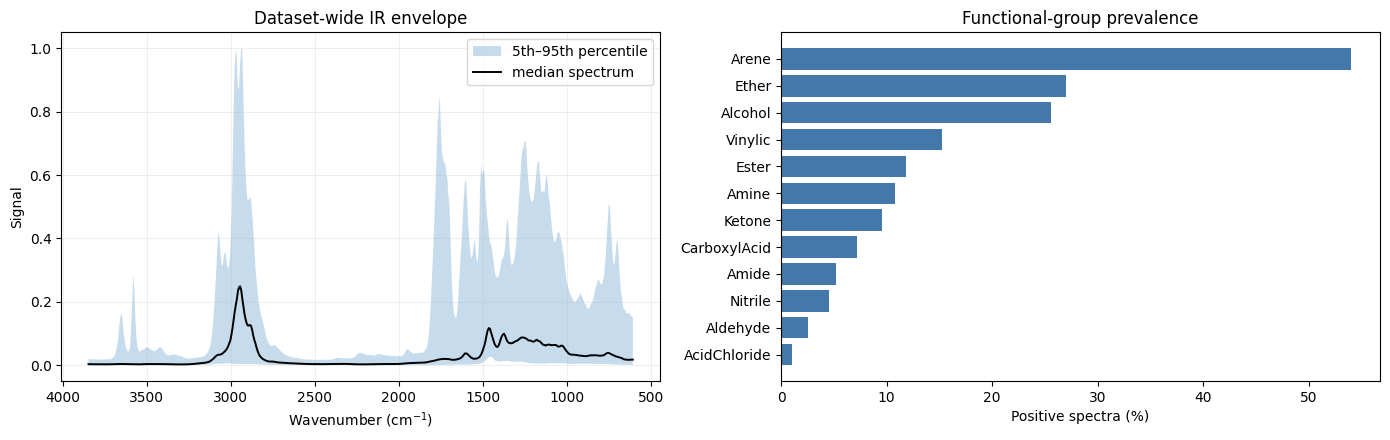

In [2]:
required = {'NIST_molecule', 'CAS_NO', 'SMILES', 'IR', 'wavenumber'} | set(LABELS)
missing = required - set(source.columns)
if missing:
    raise ValueError(f'Missing required columns: {sorted(missing)}')

def inspect_array(values):
    try:
        vector = np.asarray(values, dtype=float)
    except (TypeError, ValueError):
        return {'length': 0, 'finite': False, 'increasing': False}
    return {'length': len(vector), 'finite': vector.ndim == 1 and np.isfinite(vector).all(),
            'increasing': vector.ndim == 1 and len(vector) > 1 and np.all(np.diff(vector) > 0)}

ir_audit = source.IR.map(inspect_array).apply(pd.Series)
grid_audit = source.wavenumber.map(inspect_array).apply(pd.Series)
valid_grid_rows = source.loc[grid_audit['finite'] & grid_audit['increasing'] & grid_audit['length'].eq(TARGET_POINTS)]
reference_grid = np.asarray(valid_grid_rows.wavenumber.iloc[0], dtype=float) if len(valid_grid_rows) else None
common_grid_fraction = (valid_grid_rows.wavenumber.map(lambda value: np.array_equal(reference_grid, np.asarray(value, dtype=float))).mean()
                        if reference_grid is not None else 0.0)

print('Missing values:', source[list(required)].isna().sum().sort_values(ascending=False).to_dict())
print('Duplicate NIST IDs:', int(source.duplicated('NIST_molecule').sum()))
print('Duplicate CAS numbers:', int(source.duplicated('CAS_NO').sum()))
print('Duplicate SMILES:', int(source.duplicated('SMILES').sum()), '(inspect before deciding whether stereoisomers should be merged)')
print('IR length counts:', ir_audit['length'].value_counts().sort_index().to_dict())
print('Finite IR / finite increasing grids:', round(float(ir_audit['finite'].mean()), 3), '/', round(float((grid_audit['finite'] & grid_audit['increasing']).mean()), 3))
print(f'Fraction on the first valid {TARGET_POINTS}-point grid: {common_grid_fraction:.3f}')
print('Leakage reminder: IR is the only model feature in IR 2; NIST IDs, names, CAS numbers, SMILES, and labels must not become features.')

valid_spectra = source.loc[ir_audit['finite'] & ir_audit['length'].eq(TARGET_POINTS)]
matrix = np.vstack(valid_spectra.IR.map(lambda value: np.asarray(value, dtype=float)))
grid_for_plot = np.asarray(valid_spectra.wavenumber.iloc[0], dtype=float)
prevalence = 100 * source[LABELS].mean().sort_values(ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].fill_between(grid_for_plot, np.quantile(matrix, 0.05, axis=0), np.quantile(matrix, 0.95, axis=0), alpha=0.25, label='5th–95th percentile')
axes[0].plot(grid_for_plot, np.median(matrix, axis=0), color='black', lw=1.4, label='median spectrum')
axes[0].invert_xaxis(); axes[0].set(title='Dataset-wide IR envelope', xlabel='Wavenumber (cm$^{-1}$)', ylabel='Signal')
axes[0].legend(); axes[0].grid(alpha=0.2)
axes[1].barh(prevalence.index, prevalence.values, color='#4477AA')
axes[1].set(title='Functional-group prevalence', xlabel='Positive spectra (%)')
fig.tight_layout(); plt.show()


## Prompt 2 — propose a transparent cleansing rule

> Based only on the audit above, propose the smallest defensible IR cleansing change. First state the rule, expected row-count impact, and risks. Then implement it in the marked configuration or function below. Keep raw input immutable; record rejected-row reasons; sort/trim/regrid spectra only with an explicit policy; do not invent values outside measured wavenumbers; and preserve the label columns. Add a reloadable Parquet acceptance test.

The baseline has two intentionally visible alternatives: strict shared-grid validation, or interpolation on the measured common overlap. It does **not** pad/extrapolate. If you want to explore padding, ask the model to explain its physical justification and add a before/after plot—padding is not a neutral operation for spectroscopy.


In [3]:
def finite_spectrum(row):
    """Return sorted, de-duplicated arrays or a reason for rejection."""
    try:
        grid = np.asarray(row.wavenumber, dtype=float)
        signal = np.asarray(row.IR, dtype=float)
    except (TypeError, ValueError):
        return None, 'non-numeric spectrum'
    if grid.ndim != 1 or signal.ndim != 1 or len(grid) != len(signal) or len(grid) < 2:
        return None, 'invalid array shape'
    if not (np.isfinite(grid).all() and np.isfinite(signal).all()):
        return None, 'non-finite value'
    order = np.argsort(grid); grid, signal = grid[order], signal[order]
    unique_grid, inverse = np.unique(grid, return_inverse=True)
    if len(unique_grid) < 2:
        return None, 'fewer than two unique wavenumbers'
    signal = np.bincount(inverse, weights=signal) / np.bincount(inverse)
    return (unique_grid, signal), None

deduplicated = source.dropna(subset=['NIST_molecule', 'CAS_NO', 'SMILES']).drop_duplicates('NIST_molecule').drop_duplicates('CAS_NO').copy()
label_values_are_binary = deduplicated[LABELS].isin([0, 1]).all(axis=1)
deduplicated = deduplicated.loc[label_values_are_binary].copy()
parsed, rejected = [], []
for index, row in deduplicated.iterrows():
    spectrum, reason = finite_spectrum(row)
    if reason:
        rejected.append({'row': int(index), 'reason': reason})
    else:
        parsed.append((index, spectrum[0], spectrum[1]))
if not parsed:
    raise ValueError('No finite spectra remain after basic validation.')

if SPECTRUM_POLICY == 'strict_shared_grid':
    target_grid = parsed[0][1]
    prepared = [(index, signal) for index, grid, signal in parsed if len(grid) == TARGET_POINTS and np.array_equal(grid, target_grid)]
    rejected.extend({'row': int(index), 'reason': 'not on shared 500-point grid'}
                    for index, grid, _ in parsed if not (len(grid) == TARGET_POINTS and np.array_equal(grid, target_grid)))
elif SPECTRUM_POLICY == 'interpolate_common_overlap':
    low, high = max(grid.min() for _, grid, _ in parsed), min(grid.max() for _, grid, _ in parsed)
    if not low < high:
        raise ValueError('Spectra have no common measured wavenumber interval.')
    target_grid = np.linspace(low, high, TARGET_POINTS)
    prepared = [(index, np.interp(target_grid, grid, signal)) for index, grid, signal in parsed]
else:
    raise ValueError(f'Unknown SPECTRUM_POLICY: {SPECTRUM_POLICY}')

clean = deduplicated.loc[[index for index, _ in prepared]].copy()
clean['wavenumber'] = [target_grid.tolist()] * len(clean)
clean['IR'] = [signal.tolist() for _, signal in prepared]
clean = clean.reset_index(drop=True)
clean_matrix = np.vstack(clean.IR.map(lambda values: np.asarray(values, dtype=float)))
median = np.median(clean_matrix, axis=0)
scale = np.median(np.abs(clean_matrix - median), axis=0)
outlier_score = np.mean(np.abs(clean_matrix - median) / np.maximum(scale, 1e-8), axis=1)
clean['outlier_score'] = outlier_score
if OUTLIER_POLICY not in {'keep_and_flag', 'drop_above_quantile'}:
    raise ValueError(f'Unknown OUTLIER_POLICY: {OUTLIER_POLICY}')

print(f'Starting rows: {len(source):,}; after identifiers/labels: {len(deduplicated):,}; valid/regridded: {len(clean):,}')
print('Rejected-array reasons:', pd.Series([item['reason'] for item in rejected], dtype='object').value_counts().to_dict())
display(clean[['NIST_molecule', 'Name', 'outlier_score']].nlargest(10, 'outlier_score'))


Starting rows: 5,669; after identifiers/labels: 5,669; valid/regridded: 5,669
Rejected-array reasons: {}


,NIST_molecule,Name,outlier_score
4500,C616728,"4,6-Dinitro-m-xylene",102.397163
856,C80433,Dicumyl peroxide,101.921724
398,C118967,TNT,99.569682
4513,C1746812,Monolinuron,92.079581
2472,C22325275,"2-Mercapto-4,6-dimethylpyrimidine hydrate",90.644025
5666,C6935279,2-Benzylaminopyridine 90-180um,88.983122
5079,C87332,Isosorbide dinitrate,87.296363
5270,C71001,L-Histidine,72.360334
3702,C2832408,Disperse yellow 3,72.290961
377,C150254,Bicine,67.772330


## Prompt 3 — split first, balance only the training set

> This is a multi-label functional-group problem, so a molecule can belong to several labels. Inspect training-only label counts after a stratified train/validation/test split. Recommend either no intervention, conservative rare-label oversampling, or reducing all-zero-label rows. Explain how your choice changes prevalence and why validation/test must remain untouched. Implement only the selected training-set rule, print before/after counts and unique-molecule counts, and preserve a reproducible seed.

The starter template makes `none` the default. `oversample_rare` duplicates examples and may amplify artifacts; `undersample_unlabeled` discards examples and may discard useful negative evidence. Neither is universally correct. Make the decision from the plot and metrics, not from a model suggestion alone.


In [4]:
def split_frame(frame):
    targets = frame[LABELS].to_numpy(dtype=int)
    scarce = dict(zip(LABELS, targets.sum(axis=0)))
    if min(scarce.values()) < 3:
        raise ValueError(f'Each target needs at least three rows for three splits; counts: {scarce}')
    first = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=SPLIT_FRACTIONS['validation'] + SPLIT_FRACTIONS['test'], random_state=SEED)
    train_index, holdout_index = next(first.split(frame, targets))
    holdout = frame.iloc[holdout_index].reset_index(drop=True)
    second = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
    validation_index, test_index = next(second.split(holdout, holdout[LABELS].to_numpy(dtype=int)))
    return (frame.iloc[train_index].reset_index(drop=True),
            holdout.iloc[validation_index].reset_index(drop=True),
            holdout.iloc[test_index].reset_index(drop=True))

def balance_training(train, mode):
    """Small, visible alternatives for the exercise; never call this on validation/test."""
    rng = np.random.default_rng(SEED)
    if mode == 'none':
        return train.copy()
    if mode == 'undersample_unlabeled':
        labelled = train.loc[train[LABELS].sum(axis=1) > 0]
        unlabelled = train.loc[train[LABELS].sum(axis=1).eq(0)]
        keep = min(len(unlabelled), len(labelled))
        return pd.concat([labelled, unlabelled.sample(n=keep, random_state=SEED)], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
    if mode == 'oversample_rare':
        positive_counts = train[LABELS].sum()
        target_count = int(np.quantile(positive_counts[positive_counts > 0], 0.25))
        additions = []
        for label, count in positive_counts.items():
            if 0 < count < target_count:
                needed = min(target_count - int(count), int(count) * (MAX_OVERSAMPLE_FACTOR - 1))
                candidates = train.loc[train[label].eq(1)]
                additions.append(candidates.iloc[rng.integers(0, len(candidates), size=needed)])
        return pd.concat([train, *additions], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
    raise ValueError(f'Unknown BALANCING_MODE: {mode}')

train_base, validation, test = split_frame(clean)

def score_and_optionally_filter_outliers(train_frame, validation_frame, test_frame):
    # Fit this unsupervised rule on training spectra only; validation/test are never used to set its cutoff.
    train_matrix = np.vstack(train_frame.IR.map(lambda values: np.asarray(values, dtype=float)))
    center = np.median(train_matrix, axis=0)
    spread = np.median(np.abs(train_matrix - center), axis=0)
    def scored(frame):
        result = frame.copy()
        values = np.vstack(result.IR.map(lambda item: np.asarray(item, dtype=float)))
        result['outlier_score'] = np.mean(np.abs(values - center) / np.maximum(spread, 1e-8), axis=1)
        return result
    train_frame, validation_frame, test_frame = map(scored, (train_frame, validation_frame, test_frame))
    if OUTLIER_POLICY == 'drop_above_quantile':
        cutoff = float(train_frame.outlier_score.quantile(OUTLIER_QUANTILE))
        train_frame = train_frame.loc[train_frame.outlier_score <= cutoff].copy()
        validation_frame = validation_frame.loc[validation_frame.outlier_score <= cutoff].copy()
        test_frame = test_frame.loc[test_frame.outlier_score <= cutoff].copy()
        print(f'Applied training-derived outlier cutoff {cutoff:.3f}; check label counts after filtering.')
    return train_frame, validation_frame, test_frame

train_base, validation, test = score_and_optionally_filter_outliers(train_base, validation, test)
train = balance_training(train_base, BALANCING_MODE)
for name, frame in {'train before balance': train_base, 'train saved': train, 'validation': validation, 'test': test}.items():
    print(f'{name:20} rows={len(frame):,}; unique NIST IDs={frame.NIST_molecule.nunique():,}; positives={frame[LABELS].sum().to_dict()}')

for key in ('NIST_molecule', 'CAS_NO'):
    split_ids = [set(frame[key]) for frame in (train_base, validation, test)]
    if any(left & right for index, left in enumerate(split_ids) for right in split_ids[index + 1:]):
        raise ValueError(f'{key} appears in more than one split.')

output_columns = ['NIST_molecule', 'CAS_NO', 'Name', 'molform', 'SMILES', 'wavenumber', 'IR', 'outlier_score'] + LABELS
for frame, path in ((train, TRAIN_FILE), (validation, VALIDATION_FILE), (test, TEST_FILE)):
    frame[output_columns].to_parquet(path, index=False)

manifest = {
    'source_file': str(input_file), 'seed': SEED, 'labels': LABELS, 'feature_count': TARGET_POINTS,
    'wavenumber': target_grid.tolist(), 'split_fractions': SPLIT_FRACTIONS,
    'carpentry': {'spectrum_policy': SPECTRUM_POLICY, 'outlier_policy': OUTLIER_POLICY,
                  'outlier_quantile': OUTLIER_QUANTILE, 'balancing_mode': BALANCING_MODE},
    'rows': {'input': len(source), 'clean': len(clean), 'train_before_balance': len(train_base),
             'train': len(train), 'validation': len(validation), 'test': len(test)}
}
MANIFEST_FILE.write_text(json.dumps(manifest, indent=2), encoding='utf-8')

for path in (TRAIN_FILE, VALIDATION_FILE, TEST_FILE):
    round_trip = pd.read_parquet(path)
    if round_trip.columns.tolist() != output_columns or not round_trip.IR.map(len).eq(TARGET_POINTS).all():
        raise ValueError(f'Parquet round-trip validation failed: {path}')
print(f'Wrote train/validation/test Parquet files and manifest to {OUTPUT_DIR}.')


train before balance rows=3,968; unique NIST IDs=3,968; positives={'Vinylic': 604, 'Arene': 2145, 'Alcohol': 1016, 'Ether': 1072, 'Amine': 428, 'Nitrile': 178, 'Aldehyde': 100, 'Ketone': 379, 'CarboxylAcid': 286, 'Ester': 469, 'Amide': 205, 'AcidChloride': 40}
train saved          rows=3,968; unique NIST IDs=3,968; positives={'Vinylic': 604, 'Arene': 2145, 'Alcohol': 1016, 'Ether': 1072, 'Amine': 428, 'Nitrile': 178, 'Aldehyde': 100, 'Ketone': 379, 'CarboxylAcid': 286, 'Ester': 469, 'Amide': 205, 'AcidChloride': 40}
validation           rows=850; unique NIST IDs=850; positives={'Vinylic': 129, 'Arene': 459, 'Alcohol': 218, 'Ether': 229, 'Amine': 91, 'Nitrile': 38, 'Aldehyde': 21, 'Ketone': 81, 'CarboxylAcid': 61, 'Ester': 100, 'Amide': 44, 'AcidChloride': 8}
test                 rows=851; unique NIST IDs=851; positives={'Vinylic': 130, 'Arene': 460, 'Alcohol': 218, 'Ether': 230, 'Amine': 92, 'Nitrile': 39, 'Aldehyde': 22, 'Ketone': 82, 'CarboxylAcid': 62, 'Ester': 101, 'Amide': 44, 'Ac

Wrote train/validation/test Parquet files and manifest to outputs/carpentry.


## Handoff to IR 2

IR 2 reads only `outputs/carpentry/IR_train.parquet`, `IR_validation.parquet`, `IR_test.parquet`, and `data_manifest.json`. It scales from training data only, tunes thresholds on validation data only, and reports the untouched test set. After changing a carpentry choice here, rerun this notebook and then run IR 2 without editing it.
